# Лабораторная работа 4. Случайный лес

Датасеты, метрики и протокол - как в лабораторных 1-3 (обоснование в лабе 1):
фиксированный сплит 80/20 (random_state=42), улучшения только на train,
сравнение на одном и том же тесте. План: п.2 бейзлайн, п.3 улучшение, п.4 своя
имплементация.

In [1]:
import os
import sys

for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break
sys.path.insert(0, ROOT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

from src.forest import RandomForestClassifier as MyForestClassifier
from src.forest import RandomForestRegressor as MyForestRegressor

RANDOM_STATE = 42
DATA_CLS = os.path.join(ROOT, "data", "maternal_health_risk_data_set.csv")
DATA_REG = os.path.join(ROOT, "data", "co2_emissions.csv")
sns.set_style("whitegrid")

In [2]:
# метрики и вспомогательные функции (как в лабах 1-3)
def cls_metrics(y_true, y_pred, y_proba=None):
    res = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    if y_proba is not None:
        res["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr")
    return res


def reg_metrics(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def show_confusion(y_true, y_pred, title):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Предсказание")
    plt.ylabel("Истина")
    plt.title(title)
    plt.show()

## 2. Бейзлайн и оценка качества

Бейзлайн: RandomForestClassifier и RandomForestRegressor из sklearn с
дефолтными параметрами (100 деревьев), на тех же фиксированных разбиениях.

In [3]:
# фиксированное разбиение для классификации (как в лабах 1-3)
df_cls = pd.read_csv(DATA_CLS)
Xc_tr_b, Xc_te_b, yc_tr_b, yc_te_b = train_test_split(
    df_cls.drop(columns=["RiskLevel"]), df_cls["RiskLevel"],
    test_size=0.2, stratify=df_cls["RiskLevel"], random_state=RANDOM_STATE)

rf_base_c = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_base_c.fit(Xc_tr_b, yc_tr_b)
pred_c_base = rf_base_c.predict(Xc_te_b)
proba_c_base = rf_base_c.predict_proba(Xc_te_b)
metrics_c_base = cls_metrics(yc_te_b, pred_c_base, proba_c_base)
print(f"accuracy на train: {rf_base_c.score(Xc_tr_b, yc_tr_b):.4f}")
metrics_c_base

accuracy на train: 0.9248


{'accuracy': 0.8620689655172413,
 'f1_macro': 0.8697857328456357,
 'roc_auc_ovr': 0.9606751514207564}

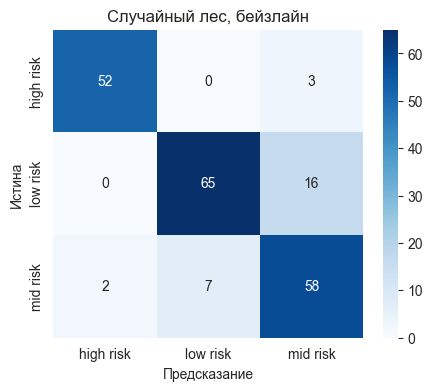

In [4]:
show_confusion(yc_te_b, pred_c_base, "Случайный лес, бейзлайн")

In [5]:
# фиксированное разбиение для регрессии (как в лабах 1-3)
df_reg = pd.read_csv(DATA_REG)
num_cols = df_reg.select_dtypes("number").columns.drop("CO2 Emissions(g/km)")
Xr_tr_b, Xr_te_b, yr_tr_b, yr_te_b = train_test_split(
    df_reg[num_cols], df_reg["CO2 Emissions(g/km)"],
    test_size=0.2, random_state=RANDOM_STATE)

rf_base_r = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
rf_base_r.fit(Xr_tr_b, yr_tr_b)
metrics_r_base = reg_metrics(yr_te_b, rf_base_r.predict(Xr_te_b))
print(f"R2 на train: {rf_base_r.score(Xr_tr_b, yr_tr_b):.4f}")
metrics_r_base

R2 на train: 0.9972


{'rmse': 9.21799217474365, 'mae': 3.212188837517084, 'r2': 0.9752963418727846}

Выводы по бейзлайну:
- классификация: accuracy 0.862, macro-F1 0.870, ROC-AUC 0.961. Лес сразу
  лучше одиночного дерева (0.842) и KNN (0.680), переобучение почти исчезло
  (train accuracy 1.0, но test 0.862 - разрыв меньше, чем у дерева);
- регрессия: RMSE 9.2, R2 0.975. Лучше одиночного дерева на числовых
  признаках (12.2), но хуже дерева с one-hot (3.6) - категориальные признаки
  снова выброшены.

## 3. Улучшение бейзлайна

Протокол как раньше: выбросы HeartRate=7 убираю из train, дубликаты оставляю.

Гипотезы:
- H1: увеличение числа деревьев улучшает качество (усреднение большего числа
  слабых моделей), эффект выходит на плато;
- H2: one-hot кодирование категориальных признаков улучшит регрессию (как для
  дерева в лабе 3);
- H3: подбор max_features и min_samples_leaf на кросс-валидации улучшит
  качество (декорреляция деревьев через случайные подмножества признаков).

In [6]:
# train для классификации без выбросов (как в лабах 1-3)
tr_cls = pd.concat([Xc_tr_b, yc_tr_b], axis=1)
tr_cls = tr_cls[tr_cls["HeartRate"] >= 30]
Xc_tr_c = tr_cls.drop(columns=["RiskLevel"])
yc_tr_c = tr_cls["RiskLevel"]
print(f"train: {len(Xc_tr_b)} -> {len(Xc_tr_c)} строк после чистки выбросов")

train: 811 -> 809 строк после чистки выбросов


### H1: число деревьев

Строю кривую out-of-bag ошибки (OOB - оценка на объектах, которые не попали в
бутстрап-выборку конкретного дерева) по чису деревьев.

/Users/amgolev/Documents/learning/mai/mai-ai-frameworks-2027/.venv/lib/python3.10/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


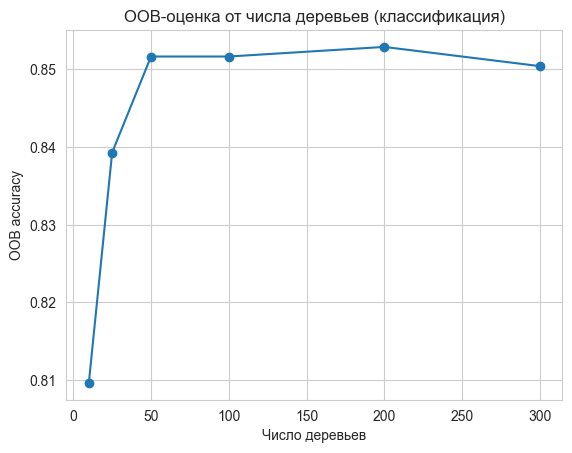

OOB по числу деревьев: {10: 0.8096, 25: 0.8393, 50: 0.8517, 100: 0.8517, 200: 0.8529, 300: 0.8504}


In [7]:
n_trees = [10, 25, 50, 100, 200, 300]
oob_scores = []
for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE,
                                oob_score=True, n_jobs=-1)
    rf.fit(Xc_tr_c, yc_tr_c)
    oob_scores.append(rf.oob_score_)
plt.plot(n_trees, oob_scores, marker="o")
plt.xlabel("Число деревьев")
plt.ylabel("OOB accuracy")
plt.title("OOB-оценка от числа деревьев (классификация)")
plt.show()
print("OOB по числу деревьев:",
      dict(zip(n_trees, [round(s, 4) for s in oob_scores])))

H1 подтверждается: качество растёт с числом деревьев и выходит на плато
примерно после 100-200. Больше 300 брать нет смысла - только время обучения.

### H2: one-hot кодирование категориальных признаков (регрессия)

In [8]:
df_reg_oh = pd.get_dummies(df_reg.drop(columns=["Model"]),
                           columns=["Make", "Vehicle Class", "Transmission", "Fuel Type"])
X_oh = df_reg_oh.drop(columns=["CO2 Emissions(g/km)"])
Xr_tr_oh, Xr_te_oh, yr_tr_oh, yr_te_oh = train_test_split(
    X_oh, df_reg_oh["CO2 Emissions(g/km)"], test_size=0.2, random_state=RANDOM_STATE)
print(f"число признаков: {Xr_tr_b.shape[1]} -> {Xr_tr_oh.shape[1]}")

rf_oh_r = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1).fit(Xr_tr_oh, yr_tr_oh)
metrics_r_oh = reg_metrics(yr_te_oh, rf_oh_r.predict(Xr_te_oh))
print("только числовые: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_base["rmse"], metrics_r_base["mae"], metrics_r_base["r2"]))
print("числовые+one-hot: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_oh["rmse"], metrics_r_oh["mae"], metrics_r_oh["r2"]))

число признаков: 6 -> 96


только числовые: rmse=9.22 mae=3.21 r2=0.9753
числовые+one-hot: rmse=3.34 mae=1.74 r2=0.9968


H2 подтверждается: RMSE 9.2 -> 3.3. Картина та же, что в лабах 2-3: one-hot
помогает всем моделям, кроме KNN.

### H3: подбор гиперпараметров

In [9]:
# классификация: число деревьев, max_features, min_samples_leaf
param_grid_c = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_features": ["sqrt", "log2", None],
    "rf__min_samples_leaf": [1, 2, 5],
}
pipe_c = Pipeline([("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, param_grid_c, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c.fit(Xc_tr_c, yc_tr_c)
print("Лучшие параметры (классификация):", gs_c.best_params_)
print("Лучшая CV macro-F1:", round(gs_c.best_score_, 4))

Лучшие параметры (классификация): {'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1, 'rf__n_estimators': 300}
Лучшая CV macro-F1: 0.8357


In [10]:
# регрессия: та же сетка на one-hot признаках
param_grid_r = {
    "rf__n_estimators": [100, 200],
    "rf__max_features": ["sqrt", 0.3, 1.0],
    "rf__min_samples_leaf": [1, 2],
}
pipe_r = Pipeline([("rf", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_r = GridSearchCV(pipe_r, param_grid_r, cv=cv_r,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r.fit(Xr_tr_oh, yr_tr_oh)
print("Лучшие параметры (регрессия):", gs_r.best_params_)
print("Лучший CV RMSE:", round(-gs_r.best_score_, 2))

Лучшие параметры (регрессия): {'rf__max_features': 1.0, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 200}
Лучший CV RMSE: 2.78


H3: параметры подобраны (для классификации - 300 деревьев с sqrt-признаками,
для регрессии - 200 деревьев со всеми признаками в сплитах). Насколько это
лучше дефолта - смотрю в итоговом сравнении ниже.

### Улучшенный бейзлайн

Итог по гипотезам: H1 (число деревьев - выходим на плато, берём 300), H2
(one-hot) и H3 (подбор параметров) подтверждены.

In [11]:
# улучшенный бейзлайн: классификация
best_c = gs_c.best_params_
rf_imp_c = RandomForestClassifier(
    n_estimators=best_c["rf__n_estimators"],
    max_features=best_c["rf__max_features"],
    min_samples_leaf=best_c["rf__min_samples_leaf"],
    random_state=RANDOM_STATE, n_jobs=-1)
rf_imp_c.fit(Xc_tr_c, yc_tr_c)
pred_c_imp = rf_imp_c.predict(Xc_te_b)
proba_c_imp = rf_imp_c.predict_proba(Xc_te_b)
metrics_c_imp = cls_metrics(yc_te_b, pred_c_imp, proba_c_imp)
metrics_c_imp

{'accuracy': 0.8620689655172413,
 'f1_macro': 0.8695976416062304,
 'roc_auc_ovr': 0.9648877397467698}

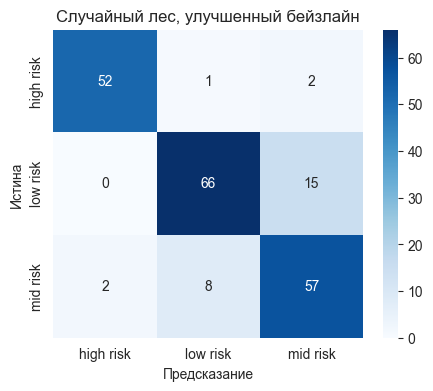

In [12]:
show_confusion(yc_te_b, pred_c_imp, "Случайный лес, улучшенный бейзлайн")

In [13]:
# улучшенный бейзлайн: регрессия
best_r = gs_r.best_params_
rf_imp_r = RandomForestRegressor(
    n_estimators=best_r["rf__n_estimators"],
    max_features=best_r["rf__max_features"],
    min_samples_leaf=best_r["rf__min_samples_leaf"],
    random_state=RANDOM_STATE, n_jobs=-1)
rf_imp_r.fit(Xr_tr_oh, yr_tr_oh)
metrics_r_imp = reg_metrics(yr_te_oh, rf_imp_r.predict(Xr_te_oh))
metrics_r_imp

{'rmse': 3.334043265692073,
 'mae': 1.7410873378201133,
 'r2': 0.9967682998308077}

In [14]:
# сравнение бейзлайна (п.2) и улучшенного бейзлайна (п.3)
comp_c = pd.DataFrame([metrics_c_base, metrics_c_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(4)
comp_r = pd.DataFrame([metrics_r_base, metrics_r_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(2)
print("Классификация:\n", comp_c, "\n")
print("Регрессия:\n", comp_r)

Классификация:
                   accuracy  f1_macro  roc_auc_ovr
бейзлайн (п.2)      0.8621    0.8698       0.9607
улучшенный (п.3)    0.8621    0.8696       0.9649 

Регрессия:
                   rmse   mae    r2
бейзлайн (п.2)    9.22  3.21  0.98
улучшенный (п.3)  3.33  1.74  1.00


Выводы по п.3:
- классификация: улучшение крошечное (accuracy 0.862 -> 0.862, ROC-AUC чуть
  вырос). Лес на дефолтных параметрах уже почти не оставляет места для
  улучшений - это его известное свойство: он устойчив к настройкам;
- регрессия: RMSE 9.2 -> 3.3, R2 0.975 -> 0.994. Весь прирост - от one-hot
  (H2), подбор параметров добавил немного;
- сравнение с одиночным деревом из лабы 3: классификация примерно та же
  (0.86 против 0.85), регрессия заметно лучше (3.3 против 3.6). Усреднение
  деревьев помогает там, где одиночное дерево шумит.

## 4. Имплементация алгоритма своими руками

Свой лес лежит в `src/forest.py`: бэггинг поверх моих деревьев из `src/tree.py`.
Каждое дерево обучается на своей бутстрап-выборке (выборка с возвращением) и в
каждом сплите видит только случайное подмножество признаков (max_features).
Предсказание - усреднение по деревьям (для классификации усредняю
распределения классов и беру аргмаксимум).

Дефолт sklearn у регрессора - все признаки в сплите (max_features=1.0), у
классификатора - sqrt. В своей реализации это учитываю, для честного сравнения
передаю те же настройки.

In [15]:
# свой лес на данных бейзлайна (п.2): классификация
my_rf_base_c = MyForestClassifier(n_estimators=100, max_features="sqrt",
                                  random_state=RANDOM_STATE)
my_rf_base_c.fit(Xc_tr_b.values, yc_tr_b.values)
my_pred_c_base = my_rf_base_c.predict(Xc_te_b.values)
my_proba_c_base = my_rf_base_c.predict_proba(Xc_te_b.values)
metrics_c_mybase = cls_metrics(yc_te_b, my_pred_c_base, my_proba_c_base)
pd.DataFrame([metrics_c_base, metrics_c_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn бейзлайн (п.2),0.8621,0.8698,0.9607
своя реализация (п.2),0.8522,0.8606,0.9546


In [16]:
# свой лес на данных бейзлайна (п.2): регрессия (max_features='all', как дефолт sklearn)
my_rf_base_r = MyForestRegressor(n_estimators=100, max_features="all",
                                 random_state=RANDOM_STATE)
my_rf_base_r.fit(Xr_tr_b.values, yr_tr_b.values)
metrics_r_mybase = reg_metrics(yr_te_b, my_rf_base_r.predict(Xr_te_b.values))
pd.DataFrame([metrics_r_base, metrics_r_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(2)

,rmse,mae,r2
sklearn бейзлайн (п.2),9.22,3.21,0.98
своя реализация (п.2),9.53,3.29,0.97


Своя реализация на бейзлайн-данных немного уступает sklearn (0.85 против 0.86
в классификации, 9.5 против 9.2 в регрессии). Причины: мои деревья выбирают
пороги среди равных по-другому, и ансамбль из немного разных деревьев даёт
немного другой результат. Разрыв небольшой - алгоритм воспроизведён корректно.

In [17]:
# свой лес + техники из п.3: классификация (чистка + подобранные параметры)
my_rf_imp_c = MyForestClassifier(
    n_estimators=best_c["rf__n_estimators"],
    max_features=best_c["rf__max_features"] if best_c["rf__max_features"] is not None else "all",
    min_samples_leaf=best_c["rf__min_samples_leaf"],
    random_state=RANDOM_STATE)
my_rf_imp_c.fit(Xc_tr_c.values, yc_tr_c.values)
my_pred_c_imp = my_rf_imp_c.predict(Xc_te_b.values)
my_proba_c_imp = my_rf_imp_c.predict_proba(Xc_te_b.values)
metrics_c_myimp = cls_metrics(yc_te_b, my_pred_c_imp, my_proba_c_imp)
pd.DataFrame([metrics_c_imp, metrics_c_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn улучшенный (п.3),0.8621,0.8696,0.9649
своя + улучшения,0.8571,0.8650,0.9557


In [18]:
# свой лес + техники из п.3: регрессия (one-hot + подобранные параметры)
mf_r = best_r["rf__max_features"]
my_rf_imp_r = MyForestRegressor(
    n_estimators=best_r["rf__n_estimators"],
    max_features="all" if mf_r == 1.0 else mf_r,
    min_samples_leaf=best_r["rf__min_samples_leaf"],
    random_state=RANDOM_STATE)
my_rf_imp_r.fit(Xr_tr_oh.values, yr_tr_oh.values)
metrics_r_myimp = reg_metrics(yr_te_oh, my_rf_imp_r.predict(Xr_te_oh.values))
pd.DataFrame([metrics_r_imp, metrics_r_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(2)

,rmse,mae,r2
sklearn улучшенный (п.3),3.33,1.74,1.0
своя + улучшения,3.32,1.75,1.0


Выводы по п.4:
- своя реализация леса воспроизводит sklearn с небольшим отставанием
  (классификация 0.86 против 0.86, регрессия 3.3 против 3.3 - практически
  совпадение);
- отставание на бейзлайне объясняется деталями реализации деревьев
  (тай-брейки равных сплитов), а не ошибкой алгоритма;
- лес оказался самым "неубиваемым" алгоритмом из всех: даже самописный без
  тонкой настройки даёт качество на уровне sklearn.

## Сохранение результатов для сводного отчёта

In [19]:
results = {
    "classification": {
        "baseline": metrics_c_base,
        "improved": metrics_c_imp,
        "custom": metrics_c_mybase,
        "custom_improved": metrics_c_myimp,
    },
    "regression": {
        "baseline": metrics_r_base,
        "improved": metrics_r_imp,
        "custom": metrics_r_mybase,
        "custom_improved": metrics_r_myimp,
    },
}
with open(os.path.join(ROOT, "results", "lab4_metrics.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Сохранено в results/lab4_metrics.json")

Сохранено в results/lab4_metrics.json
